# Lab 9 - 3D CNN Fall Detection (URFD)


In [1]:
!pip -q install kagglehub
import os, re, glob, random, time, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)
warnings.filterwarnings("ignore")

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(no GPU - enable it!)")

# ---- config ----
T          = 16     # frames per clip fed to the model (use 32 for more temporal context; slower)
CACHE_T    = 64     # frames kept per video in RAM (uniformly sampled)
CACHE_SIZE = 128    # cached frame size; random-crop to CROP during training
CROP       = 112
BATCH      = 8
EPOCHS     = 40
LR         = 1e-3

Device: cuda Tesla T4


## Task 1 - Data acquisition and exploration

In [2]:
import kagglehub
try:
    DATA_ROOT = kagglehub.dataset_download("shahliza27/ur-fall-detection-dataset")
except Exception as e:
    print("kagglehub failed:", e)
    print("Fallback: upload kaggle.json, then run the commented lines below.")
    # from google.colab import files; files.upload()
    # !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    # !kaggle datasets download -d shahliza27/ur-fall-detection-dataset -p /content/urfd --unzip
    # DATA_ROOT = "/content/urfd"
    raise
print("DATA_ROOT:", DATA_ROOT)

Using Colab cache for faster access to the 'ur-fall-detection-dataset' dataset.
DATA_ROOT: /kaggle/input/ur-fall-detection-dataset


In [3]:
# Inspect the structure. READ THIS OUTPUT - the labeling logic below depends on folder/file names.
VID_EXT = (".mp4", ".avi", ".mov", ".mkv")
IMG_EXT = (".png", ".jpg", ".jpeg")
for dp, dn, fn in os.walk(DATA_ROOT):
    depth = dp[len(DATA_ROOT):].count(os.sep)
    if depth <= 3:
        n_vid = sum(f.lower().endswith(VID_EXT) for f in fn)
        n_img = sum(f.lower().endswith(IMG_EXT) for f in fn)
        print("  " * depth + os.path.basename(dp) + f"/  [dirs={len(dn)} videos={n_vid} images={n_img}]")

ur-fall-detection-dataset/  [dirs=1 videos=0 images=0]
  UR_fall_detection_dataset_cam0_rgb/  [dirs=70 videos=0 images=0]
    adl-07-cam0-rgb/  [dirs=0 videos=0 images=180]
    adl-32-cam0-rgb/  [dirs=0 videos=0 images=200]
    adl-28-cam0-rgb/  [dirs=0 videos=0 images=85]
    fall-29-cam0-rgb/  [dirs=0 videos=0 images=99]
    fall-24-cam0-rgb/  [dirs=0 videos=0 images=60]
    fall-07-cam0-rgb/  [dirs=0 videos=0 images=156]
    fall-16-cam0-rgb/  [dirs=0 videos=0 images=55]
    adl-02-cam0-rgb/  [dirs=0 videos=0 images=180]
    adl-35-cam0-rgb/  [dirs=0 videos=0 images=280]
    fall-11-cam0-rgb/  [dirs=0 videos=0 images=130]
    fall-18-cam0-rgb/  [dirs=0 videos=0 images=65]
    fall-06-cam0-rgb/  [dirs=0 videos=0 images=100]
    fall-15-cam0-rgb/  [dirs=0 videos=0 images=71]
    adl-20-cam0-rgb/  [dirs=0 videos=0 images=270]
    fall-28-cam0-rgb/  [dirs=0 videos=0 images=66]
    adl-31-cam0-rgb/  [dirs=0 videos=0 images=250]
    adl-24-cam0-rgb/  [dirs=0 videos=0 images=70]
    adl-18

In [4]:
def rel(p): return os.path.relpath(p, DATA_ROOT).replace("\\", "/").lower()

def label_from_path(r):
    # label comes from the path RELATIVE to the dataset root (root name itself contains "fall")
    if re.search(r"(^|[^a-z])adl", r):  return 0
    if re.search(r"fall", r):           return 1
    return None

def group_from_path(r):
    m = re.search(r"(fall|adl)[-_ ]?0*(\d+)", r)
    return f"{m.group(1)}-{int(m.group(2)):02d}" if m else os.path.splitext(os.path.basename(r))[0]

def cam_from_path(r):
    m = re.search(r"cam\s*([01])", r)
    return f"cam{m.group(1)}" if m else "unknown"

samples = []
# (a) video files
for dp, _, fn in os.walk(DATA_ROOT):
    for f in fn:
        if f.lower().endswith(VID_EXT):
            p = os.path.join(dp, f); r = rel(p); y = label_from_path(r)
            if y is not None and "depth" not in r:
                samples.append(dict(path=p, kind="video", label=y, group=group_from_path(r), cam=cam_from_path(r)))
# (b) image-sequence folders (RGB only; skip depth/accel)
for dp, dn, fn in os.walk(DATA_ROOT):
    imgs = sorted(f for f in fn if f.lower().endswith(IMG_EXT))
    r = rel(dp)
    if len(imgs) >= T and "depth" not in r and "dep" not in os.path.basename(r) and not any(f.lower().endswith(VID_EXT) for f in fn):
        y = label_from_path(r)
        if y is not None:
            samples.append(dict(path=dp, kind="images", label=y, group=group_from_path(r), cam=cam_from_path(r)))

df = pd.DataFrame(samples)
assert len(df), "No samples found - check the structure printed above and fix label_from_path / extensions."
print(df.groupby(["kind", "label"]).size().unstack(fill_value=0).rename(columns={0: "ADL", 1: "FALL"}))
print("Unique sequence groups:", df.group.nunique(), "| per class:", df.drop_duplicates("group").label.value_counts().to_dict())
df.head(10)

label   ADL  FALL
kind             
images   40    30
Unique sequence groups: 70 | per class: {0: 40, 1: 30}


,path,kind,label,group,cam
0,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,0,adl-07,cam0
1,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,0,adl-32,cam0
2,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,0,adl-28,cam0
3,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,1,fall-29,cam0
4,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,1,fall-24,cam0
5,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,1,fall-07,cam0
6,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,1,fall-16,cam0
7,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,0,adl-02,cam0
8,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,0,adl-35,cam0
9,/kaggle/input/ur-fall-detection-dataset/UR_fal...,images,1,fall-11,cam0


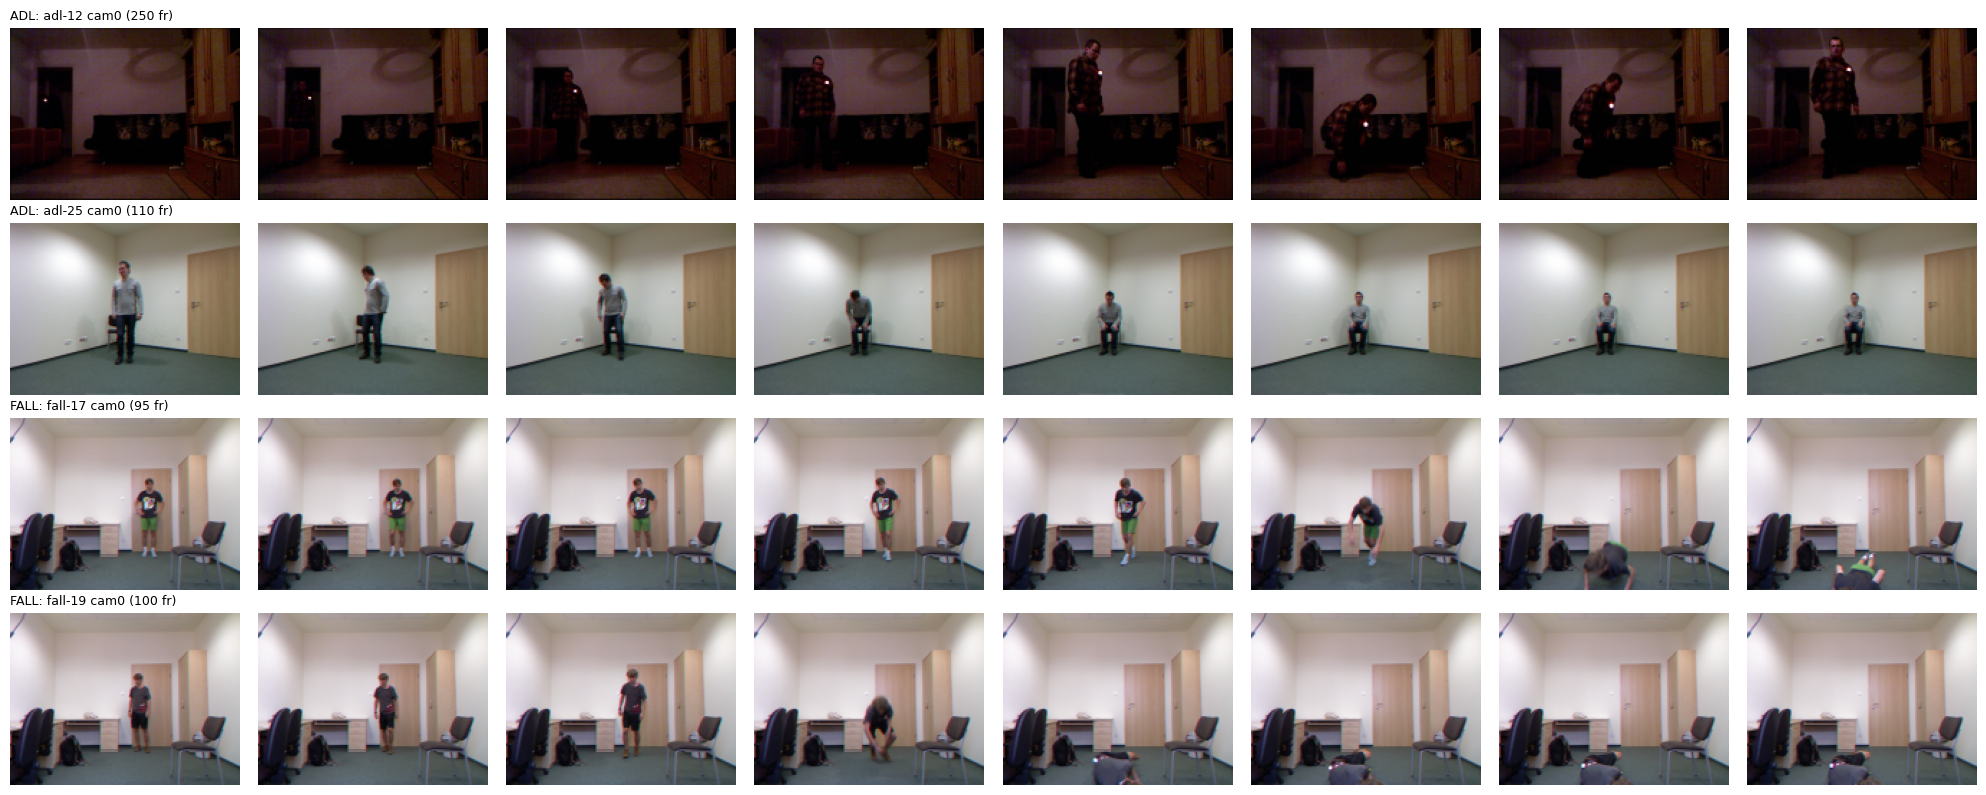

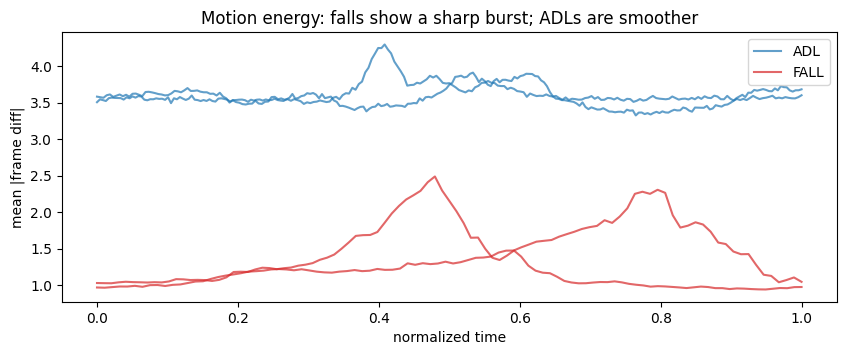

In [5]:
# Visual comparison: ADL vs FALL (frames + motion energy over time)
def read_all_frames(item, size=(160, 120), max_frames=None):
    frames = []
    if item["kind"] == "video":
        cap = cv2.VideoCapture(item["path"])
        while True:
            ok, f = cap.read()
            if not ok: break
            frames.append(cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), size, interpolation=cv2.INTER_AREA))
        cap.release()
    else:
        files = sorted(glob.glob(os.path.join(item["path"], "*")))
        files = [f for f in files if f.lower().endswith(IMG_EXT)]
        for fp in files:
            f = cv2.imread(fp)
            if f is not None: frames.append(cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), size, interpolation=cv2.INTER_AREA))
    return np.array(frames)

fig, axes = plt.subplots(4, 8, figsize=(20, 8))
for row, (lab, name) in enumerate([(0, "ADL"), (0, "ADL"), (1, "FALL"), (1, "FALL")]):
    item = df[df.label == lab].sample(1, random_state=row + 7).iloc[0].to_dict()
    fr = read_all_frames(item)
    idx = np.linspace(0, len(fr) - 1, 8).astype(int)
    for j, i in enumerate(idx):
        axes[row, j].imshow(fr[i]); axes[row, j].axis("off")
    axes[row, 0].set_title(f"{name}: {item['group']} {item['cam']} ({len(fr)} fr)", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
for lab, c, nm in [(0, "tab:blue", "ADL"), (1, "tab:red", "FALL")]:
    for k in range(2):
        item = df[df.label == lab].sample(1, random_state=100 + k).iloc[0].to_dict()
        fr = read_all_frames(item).astype(np.float32)
        me = np.abs(np.diff(fr, axis=0)).mean(axis=(1, 2, 3))
        ax.plot(np.linspace(0, 1, len(me)), me, color=c, alpha=.7, label=nm if k == 0 else None)
ax.set_xlabel("normalized time"); ax.set_ylabel("mean |frame diff|"); ax.legend(); ax.set_title("Motion energy: falls show a sharp burst; ADLs are smoother")
plt.show()

## Task 2 - Preprocessing


In [6]:
def cache_item(item):
    frames = []
    try:
        if item["kind"] == "video":
            cap = cv2.VideoCapture(item["path"])
            if not cap.isOpened(): return None
            while True:
                ok, f = cap.read()
                if not ok: break
                frames.append(cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), (CACHE_SIZE, CACHE_SIZE), interpolation=cv2.INTER_AREA))
            cap.release()
        else:
            files = sorted(f for f in glob.glob(os.path.join(item["path"], "*")) if f.lower().endswith(IMG_EXT))
            for fp in files:
                f = cv2.imread(fp)
                if f is None: return None            # corrupted frame -> drop whole sequence
                frames.append(cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), (CACHE_SIZE, CACHE_SIZE), interpolation=cv2.INTER_AREA))
    except Exception as e:
        print("  error:", item["path"], e); return None
    if len(frames) < T: return None
    idx = np.linspace(0, len(frames) - 1, min(CACHE_T, len(frames))).astype(int)
    return np.stack([frames[i] for i in idx])        # (N, H, W, 3) uint8

cache, bad = {}, []
t0 = time.time()
for i, row in df.iterrows():
    arr = cache_item(row.to_dict())
    if arr is None: bad.append(row.path)
    else: cache[i] = arr
print(f"Cached {len(cache)} sequences, removed {len(bad)} corrupted/too-short in {time.time()-t0:.0f}s")
for b in bad: print("  removed:", b)
df = df.loc[list(cache.keys())].reset_index()   # 'index' column = key into cache
print("RAM for cache: %.2f GB" % (sum(a.nbytes for a in cache.values()) / 1e9))

Cached 70 sequences, removed 0 corrupted/too-short in 262s
RAM for cache: 0.22 GB


In [7]:
# ---- 70/15/15 split, stratified, GROUPED by sequence id (no leakage across cameras/modalities) ----
groups = df.drop_duplicates("group")[["group", "label"]].reset_index(drop=True)
g_train, g_tmp = train_test_split(groups, test_size=0.30, stratify=groups.label, random_state=SEED)
g_val, g_test  = train_test_split(g_tmp, test_size=0.50, stratify=g_tmp.label, random_state=SEED)
split_of = {**{g: "train" for g in g_train.group}, **{g: "val" for g in g_val.group}, **{g: "test" for g in g_test.group}}
df["split"] = df.group.map(split_of)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0).rename(columns={0: "ADL", 1: "FALL"}))
assert not (set(g_train.group) & set(g_test.group)) and not (set(g_train.group) & set(g_val.group))

train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "val"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)

# class imbalance -> weighted cross-entropy (inverse frequency, computed on TRAIN only)
cnt = np.bincount(train_df.label, minlength=2).astype(np.float32)
class_w = torch.tensor(cnt.sum() / (2 * cnt), dtype=torch.float32).to(DEVICE)
print("train class counts [ADL, FALL]:", cnt, "| loss weights:", class_w.cpu().numpy().round(3))

label  ADL  FALL
split           
test     6     5
train   28    21
val      6     4
train class counts [ADL, FALL]: [28. 21.] | loss weights: [0.875 1.167]


In [8]:
class FallDS(Dataset):
    def __init__(self, frame_df, train):
        self.df, self.train = frame_df, train
    def __len__(self): return len(self.df)

    def _indices(self, n):
        edges = np.linspace(0, n, T + 1)
        if self.train:   # temporal jitter: random frame inside each of T segments
            return np.array([np.random.randint(int(edges[i]), max(int(edges[i]) + 1, int(edges[i + 1]))) for i in range(T)])
        return np.array([min(n - 1, int((edges[i] + edges[i + 1]) / 2)) for i in range(T)])

    def __getitem__(self, i):
        row = self.df.iloc[i]
        arr = cache[row["index"]]
        clip = torch.from_numpy(arr[self._indices(len(arr))]).permute(0, 3, 1, 2).float() / 255.0   # (T,3,H,W) in [0,1]
        if self.train:
            if random.random() < 0.5: clip = torch.flip(clip, dims=[3])                     # horizontal flip
            ang = random.uniform(-10, 10); clip = TF.rotate(clip, ang)                        # same rotation for all frames
            y0, x0 = random.randint(0, CACHE_SIZE - CROP), random.randint(0, CACHE_SIZE - CROP)  # random crop
            clip = clip[:, :, y0:y0 + CROP, x0:x0 + CROP]
        else:
            o = (CACHE_SIZE - CROP) // 2
            clip = clip[:, :, o:o + CROP, o:o + CROP]                                         # center crop
        return clip.permute(1, 0, 2, 3).contiguous(), int(row["label"]), i                    # (3,T,H,W)

train_dl = DataLoader(FallDS(train_df, True),  batch_size=BATCH, shuffle=True,  num_workers=2, drop_last=len(train_df) > BATCH)
val_dl   = DataLoader(FallDS(val_df, False),   batch_size=BATCH, shuffle=False, num_workers=2)
test_dl  = DataLoader(FallDS(test_df, False),  batch_size=BATCH, shuffle=False, num_workers=2)

x, y, _ = next(iter(train_dl))
print("batch tensor (B,C,T,H,W):", tuple(x.shape), "| range: %.2f-%.2f" % (x.min(), x.max()))
# channels-last view of one clip, matching the lab's (frames x H x W x C) description:
print("single clip as (frames,H,W,C):", tuple(x[0].permute(1, 2, 3, 0).shape))

batch tensor (B,C,T,H,W): (8, 3, 16, 112, 112) | range: 0.00-1.00
single clip as (frames,H,W,C): (16, 112, 112, 3)


## Task 3 - Model, training, evaluation

params: 3.52M
ep 01 | train loss 0.7995 | val loss 3.0371 acc 0.100 auc 0.000
ep 02 | train loss 0.3804 | val loss 8.0426 acc 0.400 auc 0.167
ep 03 | train loss 0.4161 | val loss 5.3872 acc 0.600 auc 0.625
ep 04 | train loss 0.3781 | val loss 1.4829 acc 0.500 auc 0.750
ep 05 | train loss 0.3788 | val loss 1.0091 acc 0.600 auc 0.875
ep 06 | train loss 0.1942 | val loss 0.9425 acc 0.600 auc 1.000
ep 07 | train loss 0.2601 | val loss 0.7529 acc 0.700 auc 1.000
ep 08 | train loss 0.3139 | val loss 0.6447 acc 0.800 auc 1.000
ep 09 | train loss 0.3941 | val loss 0.2683 acc 0.900 auc 0.917
ep 10 | train loss 0.2620 | val loss 3.3642 acc 0.600 auc 0.625
ep 11 | train loss 0.2205 | val loss 1.7636 acc 0.600 auc 1.000
ep 12 | train loss 0.1142 | val loss 0.3852 acc 0.700 auc 1.000
ep 13 | train loss 0.1087 | val loss 1.0324 acc 0.600 auc 0.917
ep 14 | train loss 0.1789 | val loss 0.1215 acc 1.000 auc 1.000
ep 15 | train loss 0.1447 | val loss 0.2407 acc 0.900 auc 1.000
ep 16 | train loss 0.0395 

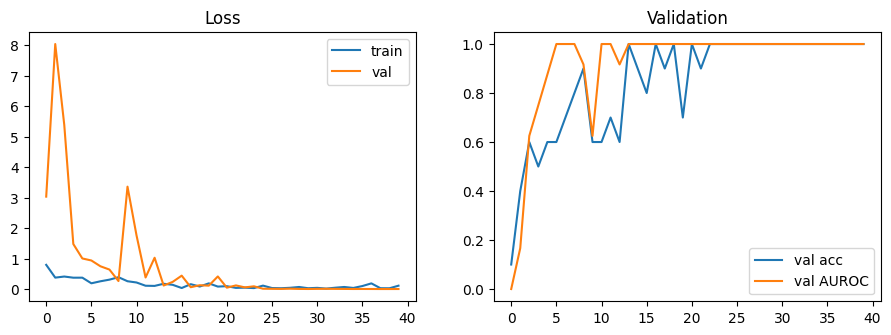

In [9]:
class Block(nn.Module):
    def __init__(self, cin, cout, pool):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
            nn.Conv3d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
            nn.MaxPool3d(pool))
    def forward(self, x): return self.net(x)

class Fall3DCNN(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            Block(3, 32, (1, 2, 2)),     # keep temporal resolution early
            Block(32, 64, (2, 2, 2)),
            Block(64, 128, (2, 2, 2)),
            Block(128, 256, (2, 2, 2)))
        self.head = nn.Sequential(nn.AdaptiveAvgPool3d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

model = Fall3DCNN().to(DEVICE)
print("params: %.2fM" % (sum(p.numel() for p in model.parameters()) / 1e6))
criterion = nn.CrossEntropyLoss(weight=class_w)
optim = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == "cuda")

@torch.no_grad()
def predict(dl):
    model.eval(); P, Y, I, L = [], [], [], 0.0
    for x, y, i in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            out = model(x)
        L += criterion(out.float(), y).item() * len(y)
        P.append(F.softmax(out.float(), 1)[:, 1].cpu().numpy()); Y.append(y.cpu().numpy()); I.append(i.numpy())
    return np.concatenate(P), np.concatenate(Y), np.concatenate(I), L / len(dl.dataset)

def safe_auc(y, p): return roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan")

hist, best_val, best_state, patience, bad_ep = [], 1e9, None, 12, 0
for ep in range(1, EPOCHS + 1):
    model.train(); tl, n = 0.0, 0
    for x, y, _ in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optim.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            out = model(x)
        loss = criterion(out.float(), y)
        scaler.scale(loss).backward(); scaler.step(optim); scaler.update()
        tl += loss.item() * len(y); n += len(y)
    sched.step()
    p, yv, _, vl = predict(val_dl)
    vacc, vauc = accuracy_score(yv, p > .5), safe_auc(yv, p)
    hist.append((tl / n, vl, vacc, vauc))
    print(f"ep {ep:02d} | train loss {tl/n:.4f} | val loss {vl:.4f} acc {vacc:.3f} auc {vauc:.3f}")
    if vl < best_val:
        best_val, bad_ep = vl, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_fall3dcnn.pt")
    else:
        bad_ep += 1
        if bad_ep >= patience: print("early stop"); break

model.load_state_dict(best_state)
h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 0], label="train"); ax[0].plot(h[:, 1], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h[:, 2], label="val acc"); ax[1].plot(h[:, 3], label="val AUROC"); ax[1].set_title("Validation"); ax[1].legend()
plt.show()

Test sequences: 11 (5 fall / 6 ADL)
Accuracy     1.0
Precision    1.0
Recall       1.0
F1           1.0
AUROC        1.0


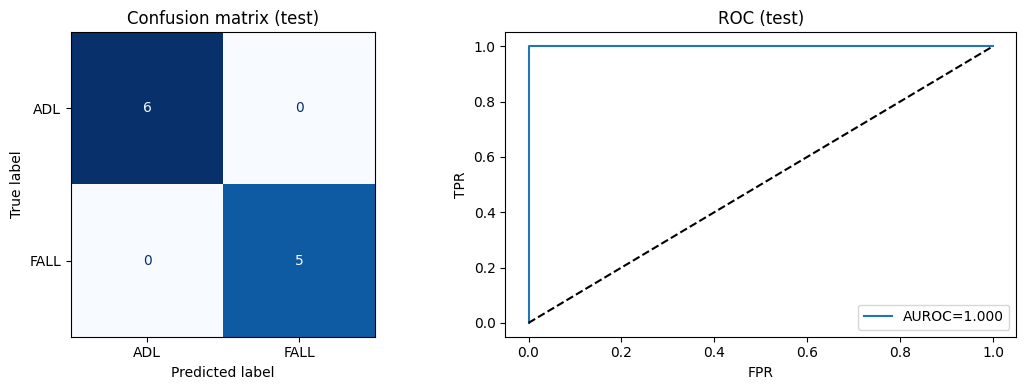

Missed falls (FN) are the costly error in elder care; FN = 0 | false alarms (FP) = 0


In [10]:
# ---- Test evaluation (threshold fixed at 0.5; test set touched once) ----
p, y, idx, tl = predict(test_dl)
pred = (p > 0.5).astype(int)
metrics = {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
           "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
           "AUROC": safe_auc(y, p)}
print(f"Test sequences: {len(y)} ({int(y.sum())} fall / {int((1-y).sum())} ADL)")
print(pd.Series(metrics).round(4).to_string())

cm = confusion_matrix(y, pred, labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=["ADL", "FALL"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (test)")
if len(np.unique(y)) > 1:
    fpr, tpr, _ = roc_curve(y, p)
    ax[1].plot(fpr, tpr, label=f"AUROC={metrics['AUROC']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
    ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].set_title("ROC (test)"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Missed falls (FN) are the costly error in elder care; FN =", cm[1, 0], "| false alarms (FP) =", cm[0, 1])

### Error analysis: camera view, occlusion, motion blur

In [11]:
def blur_score(arr):   # mean variance of Laplacian over cached frames; LOWER = blurrier
    return float(np.mean([cv2.Laplacian(cv2.cvtColor(f, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var() for f in arr]))
def motion_score(arr): # mean absolute frame difference
    a = arr.astype(np.float32); return float(np.abs(np.diff(a, axis=0)).mean())

res = test_df.iloc[idx].copy()
res["prob_fall"], res["pred"], res["true"] = p, pred, y
res["correct"] = res.pred == res.true
res["blur"]   = [blur_score(cache[k]) for k in res["index"]]
res["motion"] = [motion_score(cache[k]) for k in res["index"]]
show = res[["group", "cam", "true", "pred", "prob_fall", "blur", "motion", "correct"]].sort_values("correct")
print(show.round(3).to_string(index=False))

print("\nAccuracy by camera:"); print(res.groupby("cam").correct.agg(["mean", "count"]).round(3))
print("\nMean blur / motion, correct vs wrong:"); print(res.groupby("correct")[["blur", "motion"]].mean().round(2))

wrong = res[~res.correct]
if len(wrong):
    fig, axes = plt.subplots(len(wrong), 8, figsize=(18, 2.3 * len(wrong)), squeeze=False)
    for r, (_, row) in enumerate(wrong.iterrows()):
        arr = cache[row["index"]]; ii = np.linspace(0, len(arr) - 1, 8).astype(int)
        for j, k in enumerate(ii): axes[r, j].imshow(arr[k]); axes[r, j].axis("off")
        axes[r, 0].set_title(f"{row.group} {row.cam} true={'FALL' if row.true else 'ADL'} pred={'FALL' if row.pred else 'ADL'} p={row.prob_fall:.2f}", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("No misclassifications on this test split - that is a property of a ~10-sequence test set, not proof of robustness.")

  group  cam  true  pred  prob_fall     blur  motion  correct
fall-16 cam0     1     1      0.999  526.329   1.753     True
fall-06 cam0     1     1      0.999  641.320   2.742     True
 adl-40 cam0     0     0      0.017  296.452   2.006     True
 adl-34 cam0     0     0      0.024  387.291   2.120     True
 adl-01 cam0     0     0      0.001 1658.571   3.947     True
fall-27 cam0     1     1      0.995  493.445   1.714     True
 adl-21 cam0     0     0      0.000  211.672   3.557     True
 adl-37 cam0     0     0      0.022  521.310   3.679     True
 adl-25 cam0     0     0      0.059  252.929   0.693     True
fall-10 cam0     1     1      0.999  560.409   2.836     True
fall-25 cam0     1     1      0.998  503.466   1.548     True

Accuracy by camera:
      mean  count
cam              
cam0   1.0     11

Mean blur / motion, correct vs wrong:
           blur  motion
correct                
True     550.29    2.42
No misclassifications on this test split - that is a property of a ~10